In [4]:
import Augmentor
import glob
from skimage import io
from corebreakout.utils.viz_utils import show_images

In [5]:
img_path = '/home/administrator/Dropbox/core_data/segmentation/royal_smaller_images/'
mask_path = '/home/administrator/Dropbox/core_data/segmentation/royal_smaller_masks/'

In [6]:
p = Augmentor.Pipeline(img_path)
p.ground_truth(mask_path)

Initialised with 6 image(s) found.
Output directory set to /home/administrator/Dropbox/core_data/segmentation/royal_smaller_images/output.6 ground truth image(s) found.


In [7]:
p.crop_random(1.0, percentage_area=0.5)
p.rotate(1.0, max_left_rotation=5, max_right_rotation=5)
p.flip_left_right(0.5)
p.flip_top_bottom(0.25)
p.random_color(0.75, min_factor=0.75, max_factor=1.25)
p.shear(0.5, max_shear_left=10, max_shear_right=10)
p.skew(0.75, magnitude=0.15)

p.gaussian_distortion(0.5, 10, 10, 5, 'bell', 'in')

# brightness causes problems on the masks
#p.random_brightness(0.75, min_factor=0.8, max_factor=1.2)

In [8]:
p.sample(300)

Processing <PIL.Image.Image image mode=RGB size=610x882 at 0x7FAED8263908>: 100%|██████████| 300/300 [01:14<00:00,  4.05 Samples/s]


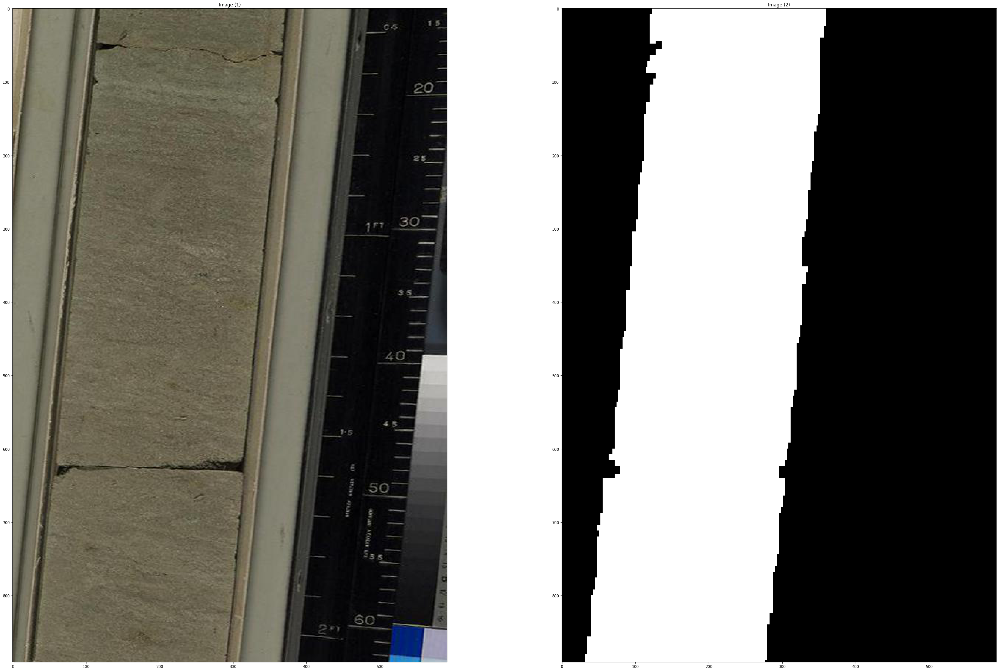

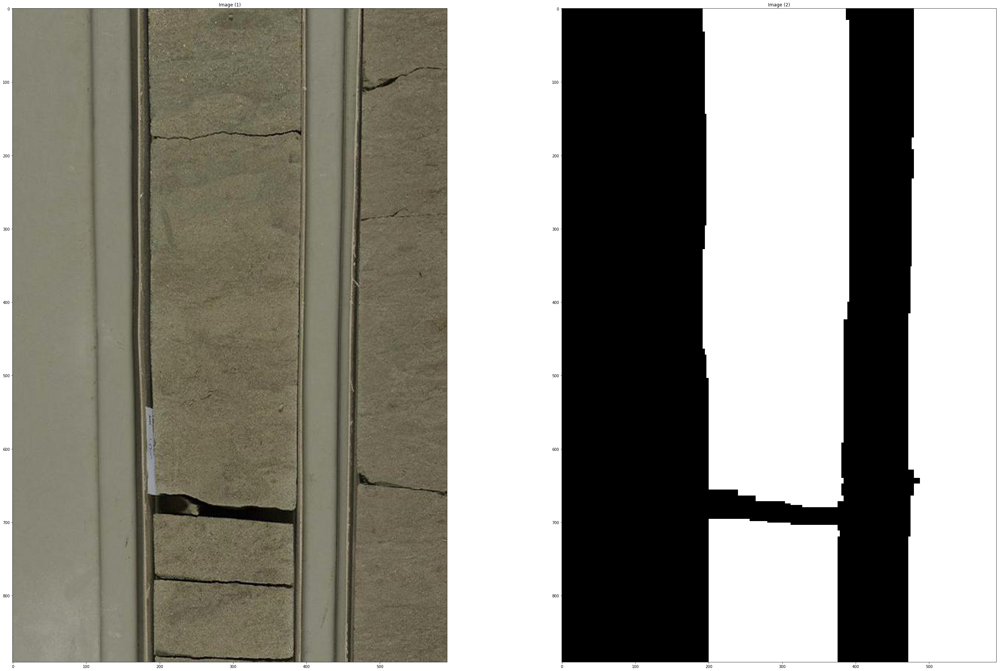

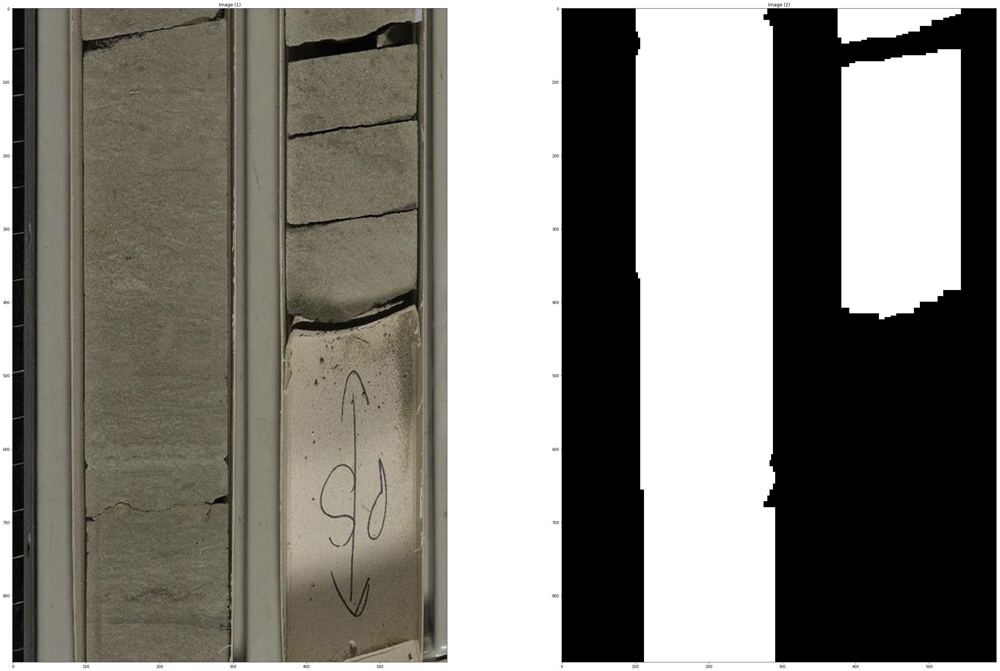

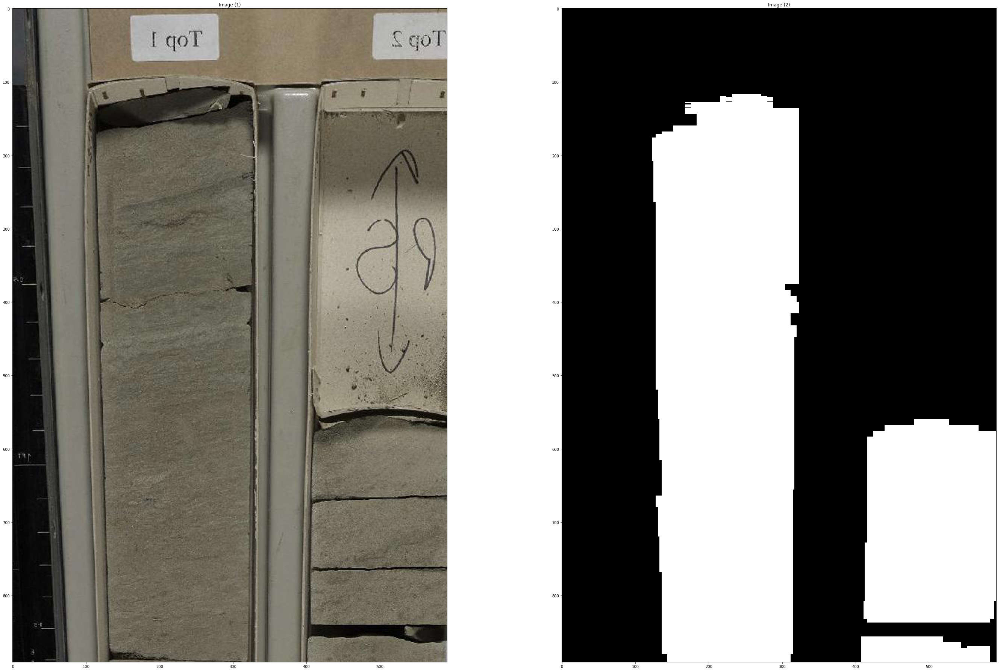

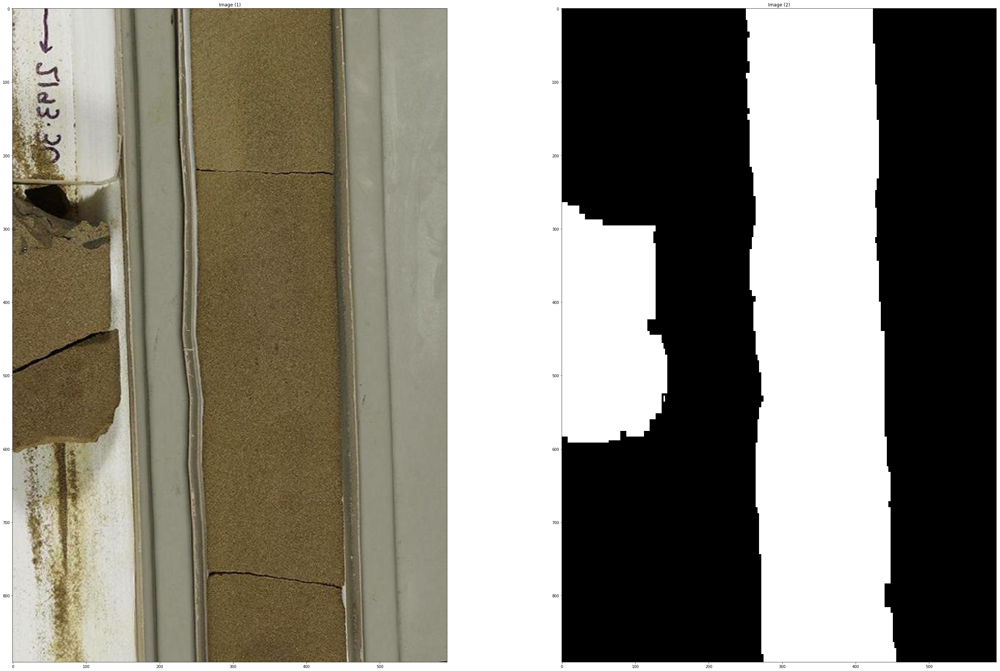

...

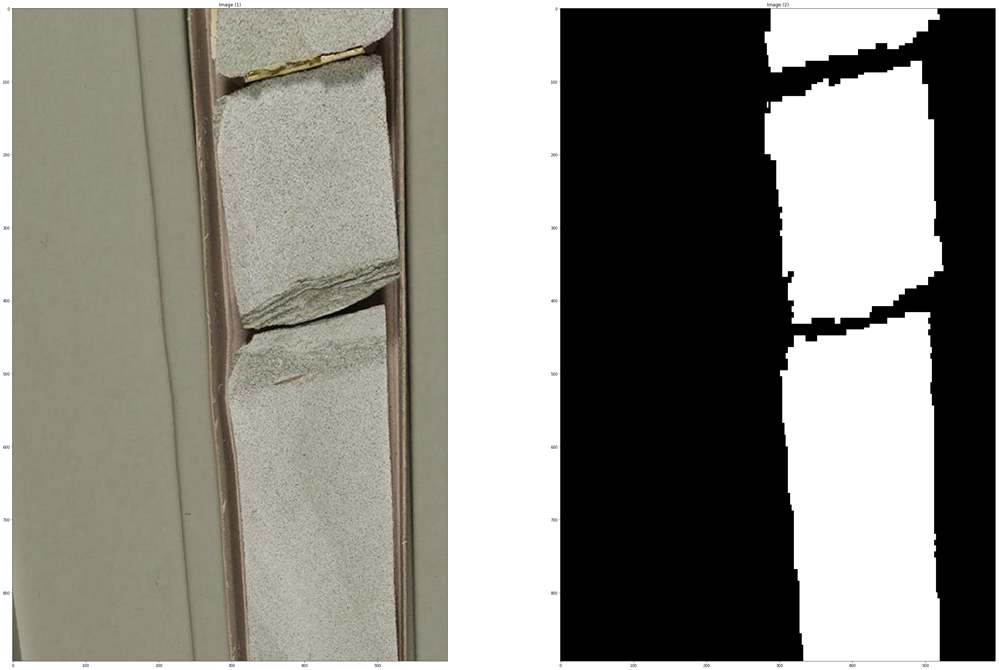

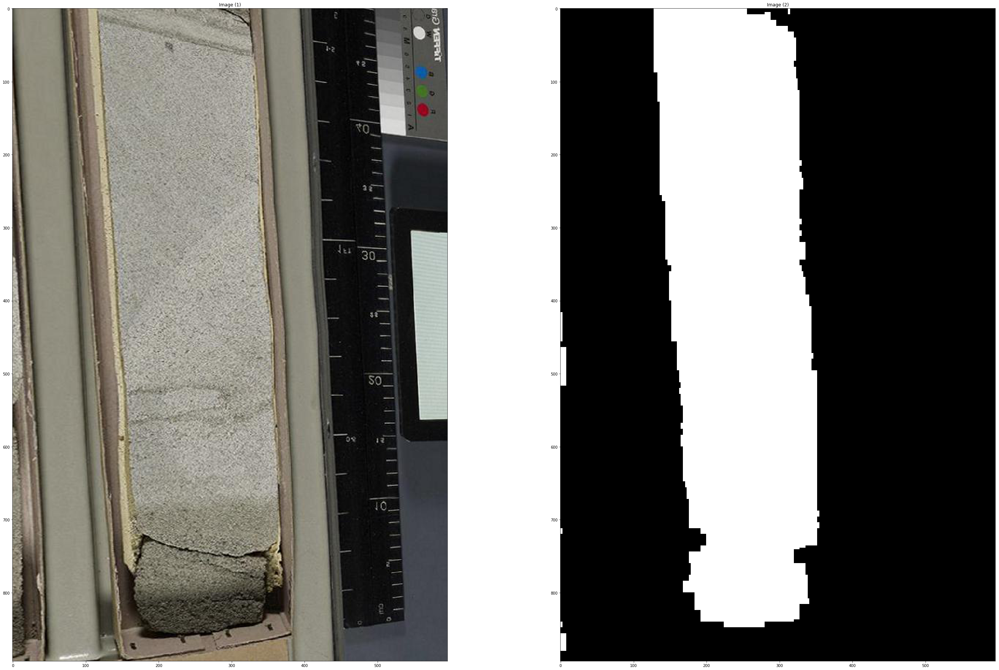

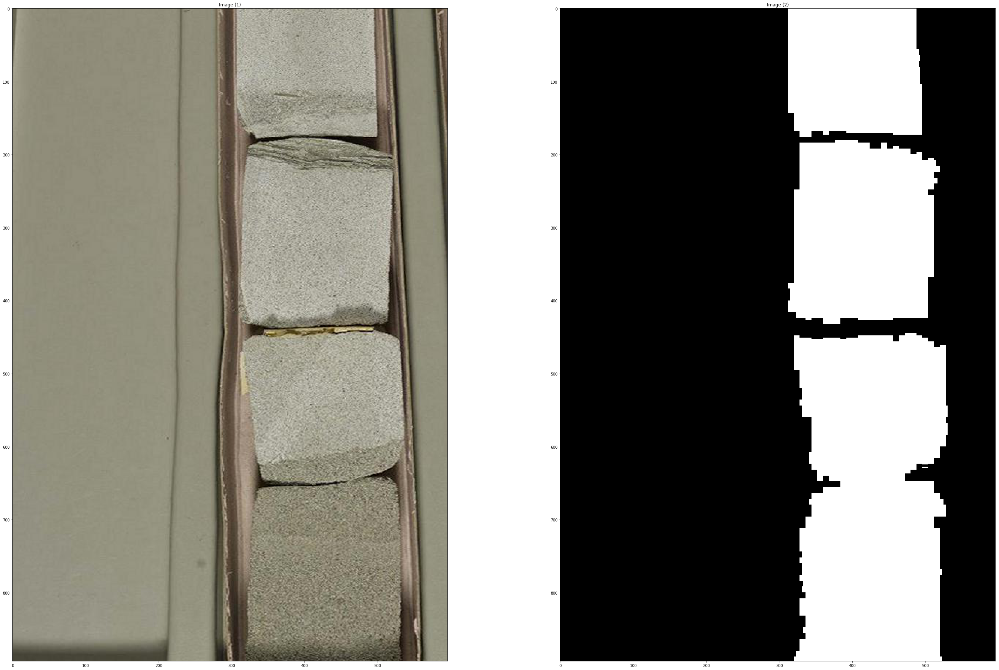

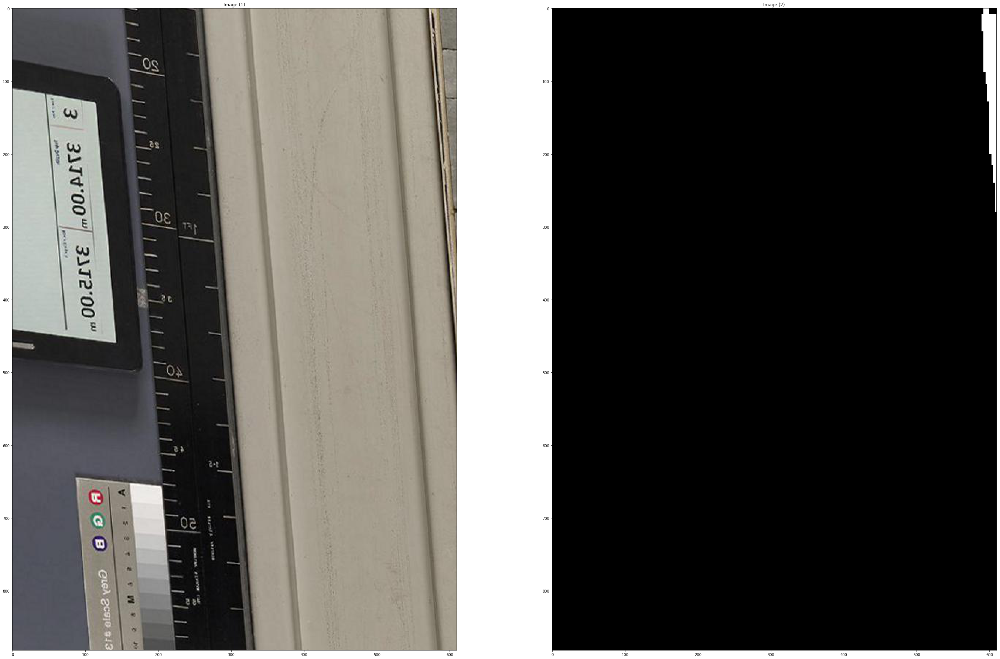

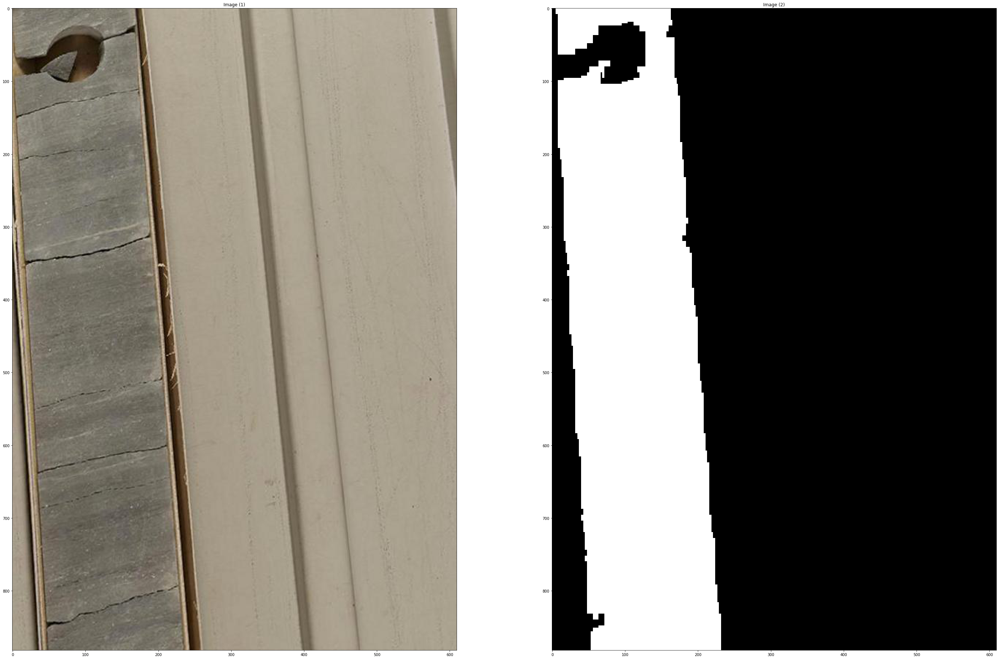

In [10]:
files = sorted(glob.glob(img_path + 'output/*jpeg'))
n = len(files) // 2
fpairs = zip(files[n:], files[:n])

ishapes = []
mshapes = []
for i, (img, m) in enumerate(fpairs):
    image = io.imread(img)
    mask = io.imread(m)>0
    if i % 15 == 0:
        show_images([image, mask])
    ishapes.append(image.shape)
    mshapes.append(mask.shape)

In [15]:
import matplotlib.pyplot as plt
import numpy as np

np.unique(ishapes), np.unique(mshapes)

(array([  3, 592, 596, 610, 882, 891, 894]),
 array([592, 596, 610, 882, 891, 894]))

## Re-savey Save

In [17]:
from skimage import io, transform
import glob

outshape = (890, 610) # take the middle shape, and must be even
save_dir = '/home/administrator/Dropbox/core_data/segmentation/royal_augmented/'

# remove '.jpeg_' --> '_'
def augpath_to_uname(s):
    f = s.split('/')[-1]
    # there's a stupid jpeg in the middle of filename
    f = f.replace('.jpeg_', '_')
    if f.find('original') != -1:
        suffix = ''
    else:
        suffix = '_ground'
    return f[f.index('S0'):-5] + suffix + '.jpeg'

files = sorted(glob.glob(img_path + 'output/*jpeg'))
n = len(files) // 2
fpairs = zip(files[n:], files[:n])
for i, m in fpairs:
    img = transform.resize(io.imread(i), outshape)
    mask = transform.resize(io.imread(m), outshape)
    io.imsave(save_dir+augpath_to_uname(i), img)
    io.imsave(save_dir+augpath_to_uname(m), (mask>0).astype(int))

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:84: UserWarning: The default mode, 'constant', will be changed to 'reflect' in skimage 0.15.
  warn("The default mode, 'constant', will be changed to 'reflect' in "
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/util/dtype.py:122: UserWarning: Possible precision loss when converting from float64 to uint8
  .format(dtypeobj_in, dtypeobj_out))
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102592_00a14701-d660-48d3-91c0-e08e519f2c09_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/util/dtype.py:118: UserWarning: Possible sign loss when converting negative image of type int64 to positive image of type uint8.
  .format(d

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102592_68c56a1f-41ec-46e4-b391-391fa0acabb9_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102592_6ac81e65-8572-4152-9c1b-564d433d5e6f_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102592_7381c33d-d563-4839-80c1-996a48d76584_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:1

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102592_fce66a38-767a-45c9-9a13-d67879b3750d_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102592_ff95a48a-7a15-4090-87ba-51d272021789_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102673_03acba0e-d253-45e3-943f-c3b07d483975_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:1

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102673_a144cc62-6b05-497b-a2d9-a32fb78c26ff_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102673_a16c5c29-1795-4fb4-8f1c-0610cf8be046_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102673_a3b557d4-b408-4ed5-aeee-bfbc7892c22c_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:1

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102695_2e25d5b0-a386-4acc-bdb4-74f3cb58a59d_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102695_2ec2915f-4b64-4518-8ed9-a27495baf7af_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102695_3b07be7b-b40b-4893-b68e-8aaaddda99c7_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:1

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102695_d955ef3e-3ce7-40c3-843c-7a770b6ec4f9_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102695_d9a8b165-f49f-4f1f-a0ca-67428eb901cc_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00102695_dc4a6dba-1995-4f7a-afd9-d0336337bb01_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:1

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106067_8bd145d6-b1f0-41e9-861a-2f7ea255fbbe_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106067_8c6540ad-2019-4423-b3eb-7b8038b8ed18_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106067_8eea8fdb-b5ea-4144-923a-4f1901265ac0_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:1

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106067_f8446cdc-5bce-4731-9b5c-45f276d10009_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106067_fd43d734-4f73-42cc-82e0-e28265957dd7_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106067_fd88ffcb-63c7-4450-a3b3-49a5ef4c91be_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:1

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106080_82ca03d4-14d2-42e6-9313-fddb9cfaea43_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106080_840e5f2c-dc5c-4b7c-a590-a75832cc58d3_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106080_8cb8ffcf-d880-466d-b10e-0a7e70f34b9f_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:1

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106080_f0b08ff1-1700-4ab1-9f6d-92259dd79d3e_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106080_f2f49a6a-ea46-482a-8a6a-66e0c4b00d0f_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00106080_f30e57ae-551c-4a7b-942e-63b1a44525e4_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:1

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00170017_7245bbe1-d876-4b8c-9697-71c67e35a256_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00170017_776c3e15-76a5-4fc8-9c18-e493de6ba11f_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:132: UserWarning: /home/administrator/Dropbox/core_data/segmentation/royal_augmented/S00170017_7d06b09c-86f9-4ea6-a232-a86637017d5b_ground.jpeg is a low contrast image
  warn('%s is a low contrast image' % fname)
/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/io/_io.py:1